<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/03_computer_vision/04_object_detection_app_african_wildlife.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🦏 Application · Object detection: an AI ranger for African wildlife

Counting animals is the first step to protecting them. Rangers and ecologists set up **camera traps**, fly **drones**
and small planes over parks, then spend weeks looking at millions of pictures to count elephants, rhinos or zebras.
Meanwhile, poaching pushed several rhino species to the brink: knowing *where* the animals are, *now*, matters.

Object detection automates the boring part: a model scans every frame, draws a box around each animal and names it.
Humans only review the interesting images. Kaggle's *iWildCam* competitions and many Zindi conservation challenges
are built on exactly this idea.

**Dataset:** *African Wildlife* (Ultralytics), ~1 500 photos of 4 iconic species: **buffalo, elephant, rhino and
zebra**, with a box around each animal.
**Your mission:** fine-tune YOLO26n to detect and count them. **Metric:** mAP50-95 (and mAP50).

| Step | Why |
|---|---|
| 1. Explore images & labels | how many boxes, how big, which classes |
| 2. Zero-shot with a COCO model | what does a generic detector already know? |
| 3. Fine-tune YOLO26n | teach it our 4 species |
| 4. Evaluate per class + test set | trust, but verify |
| 5. Confidence threshold & gallery | choose the operating point |
| 6. Wildlife census + submission | the deliverable |

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import os, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

os.environ["YOLO_VERBOSE"] = "False"          # quiet logs ("True" to watch every training step)
from ultralytics import YOLO
from ultralytics.utils import YAML
from ultralytics.utils.checks import check_yaml

DEVICE = get_device()
YOLO_DATA = DATA_DIR / "yolo_datasets"
WEIGHTS = DATA_DIR / "weights"
WEIGHTS.mkdir(exist_ok=True)


def yolo_dataset(yaml_name: str) -> Path:
    """Download an Ultralytics dataset into data/yolo_datasets/ and return a YAML pointing to it."""
    cfg = YAML.load(check_yaml(f"{yaml_name}.yaml"))
    folder = YOLO_DATA / Path(cfg["path"]).name
    if not folder.exists():
        url = cfg["download"]
        stem = Path(url).stem
        archive = download(url, YOLO_DATA / Path(url).name)
        tmp = extract(archive, YOLO_DATA / f"_tmp_{stem}")
        inner = tmp / stem if (tmp / stem).is_dir() else tmp
        shutil.move(str(inner), str(folder))
        shutil.rmtree(tmp, ignore_errors=True)
        archive.unlink()
    cfg["path"] = str(folder)
    cfg.pop("download", None)
    out = YOLO_DATA / f"{yaml_name}.yaml"
    YAML.save(out, cfg)
    return out

quest("An AI ranger for African wildlife", chapter="Track 3 · Computer vision · Object detection", xp=250)

⚙️  Using device: mps  (Apple Silicon GPU (Metal))
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · An AI ranger for African wildlife
   Track 3 · Computer vision · Object detection
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Explore the dataset 🔍

In [3]:
data_yaml = yolo_dataset("african-wildlife")          # ~105 MB, downloaded once
root = YOLO_DATA / "african-wildlife"
NAMES = YAML.load(data_yaml)["names"]

rows = []
for split in ["train", "val", "test"]:
    for lbl in (root / "labels" / split).glob("*.txt"):
        for line in lbl.read_text().splitlines():
            c, xc, yc, w, h = line.split()
            rows.append(dict(split=split, image=lbl.stem, cls=NAMES[int(c)], w=float(w), h=float(h)))
boxes = pd.DataFrame(rows)
boxes["area_%"] = 100 * boxes["w"] * boxes["h"]

print(boxes.groupby("split")["image"].nunique().rename("images").to_string(), "\n")
pd.crosstab(boxes["cls"], boxes["split"], margins=True)

split
test      227
train    1052
val       225 



split,test,train,val,All
cls,,,,
buffalo,66,399,89,554
elephant,99,558,91,748
rhino,75,399,85,559
zebra,135,575,114,824
All,375,1931,379,2685


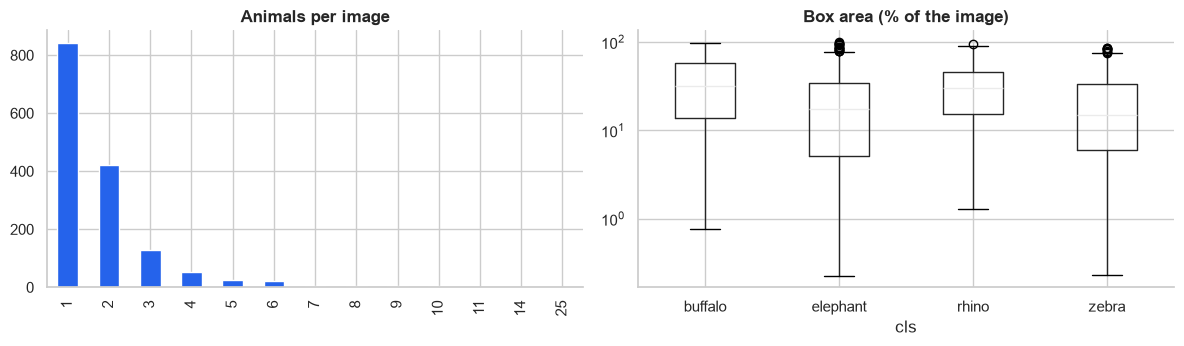

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
boxes.groupby("image").size().value_counts().sort_index().plot.bar(ax=axes[0], title="Animals per image")
boxes.boxplot(column="area_%", by="cls", ax=axes[1]); axes[1].set_title("Box area (% of the image)"); axes[1].set_yscale("log")
plt.suptitle(""); plt.tight_layout(); plt.show()

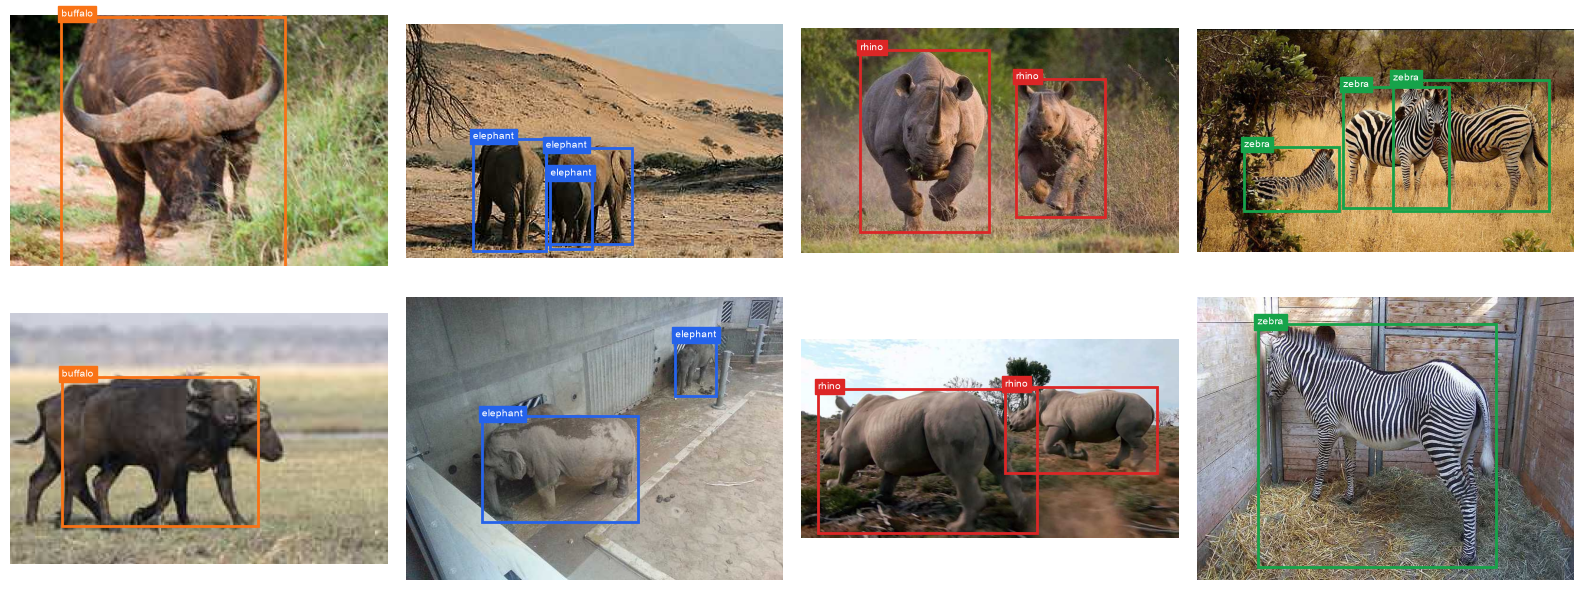

In [5]:
COLORS = {"buffalo": "#f97316", "elephant": "#2563eb", "rhino": "#dc2626", "zebra": "#16a34a"}

def show_gt(stems, split="train", ncols=4):
    fig, axes = plt.subplots(int(np.ceil(len(stems) / ncols)), ncols, figsize=(4 * ncols, 3.3 * np.ceil(len(stems) / ncols)))
    for ax, stem in zip(np.ravel(axes), stems):
        img = Image.open(root / "images" / split / f"{stem}.jpg"); W, H = img.size
        ax.imshow(img); ax.axis("off")
        for line in (root / "labels" / split / f"{stem}.txt").read_text().splitlines():
            c, xc, yc, w, h = map(float, line.split())
            name = NAMES[int(c)]
            ax.add_patch(patches.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H, fill=False,
                                           color=COLORS[name], lw=2))
            ax.text((xc - w / 2) * W, (yc - h / 2) * H, name, color="white", backgroundcolor=COLORS[name], fontsize=7)
    plt.tight_layout(); plt.show()

show_gt(boxes[boxes.split == "train"].groupby("cls")["image"].first().tolist()
        + boxes[boxes.split == "train"].groupby("cls")["image"].last().tolist())

**Observations:** the 4 classes are reasonably balanced; most images contain 1 to 3 animals, but some herds have more;
boxes are often large (close-up photos) with a long tail of small, distant animals, which are the hardest to detect.

## 2. What does a generic detector already know? 🤔

YOLO26n pre-trained on COCO knows 80 classes, including **elephant** and **zebra**… but not buffalo or rhino. Let's
see how it reacts to our photos.

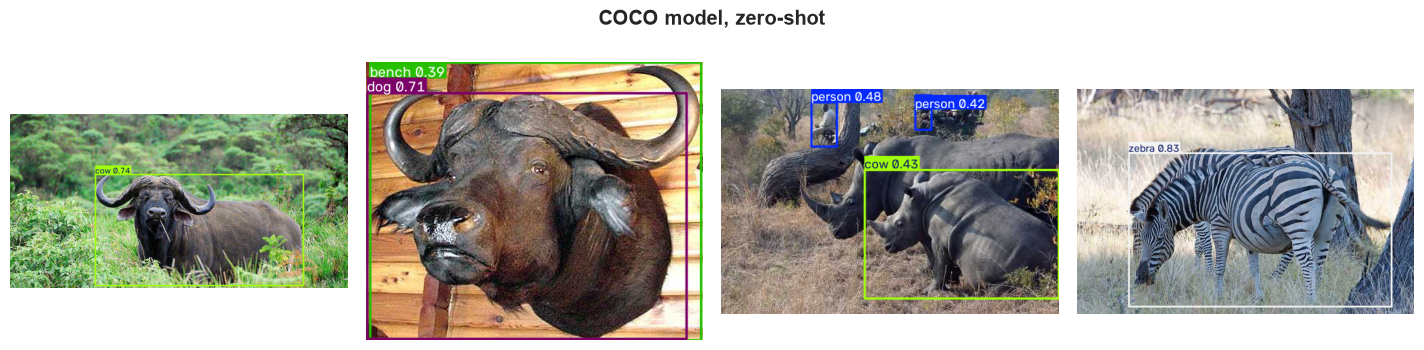

In [6]:
coco_model = YOLO(str(WEIGHTS / "yolo26n.pt"))
val_imgs = sorted((root / "images" / "val").glob("*.jpg"))
sample = [val_imgs[i] for i in (0, 60, 120, 180)]
res = coco_model.predict(sample, conf=0.3, device=DEVICE)
show_images([r.plot()[..., ::-1] for r in res], ncols=4, size=3.6, suptitle="COCO model, zero-shot")

Zebras are recognised, but buffaloes and rhinos become *cows* or *dogs*, and a few tree stumps turn into *people*. Generic
knowledge is a great **starting point**, not a solution: let's fine-tune.

## 3. Fine-tune YOLO26n 🏋️

What happens during training:
- images are resized to `imgsz` pixels and **augmented** (mosaic of 4 images, flips, colour changes, scaling),
- the network predicts boxes, the loss compares them with the labels (box position + class),
- after each epoch, the model is evaluated on the validation set; the best weights are kept (`best.pt`).

We train 12 epochs at 416 px (~1 minute per epoch on an Apple M4 Pro, a few minutes per epoch on a laptop CPU).
In a real competition you would train 50-100 epochs at 640 px.

In [7]:
model = YOLO(str(WEIGHTS / "yolo26n.pt"))
t0 = time.time()
metrics = model.train(data=str(data_yaml), epochs=12, imgsz=416, batch=16, device=DEVICE, workers=NUM_WORKERS,
                      project=str(RUNS_DIR / "wildlife"), name="yolo26n", exist_ok=True,
                      plots=False, deterministic=False, seed=SEED)
print(f"⏱️  {(time.time() - t0) / 60:.1f} min · val mAP50 = {metrics.box.map50:.3f} · mAP50-95 = {metrics.box.map:.3f}")

lb = Leaderboard("african_wildlife", metric="val_mAP50-95")
lb.add("YOLO26n · 12 epochs · 416px", metrics.box.map, mAP50=round(metrics.box.map50, 3))

⏱️  16.3 min · val mAP50 = 0.953 · mAP50-95 = 0.793
📋 YOLO26n · 12 epochs · 416px: val_mAP50-95 = 0.79272


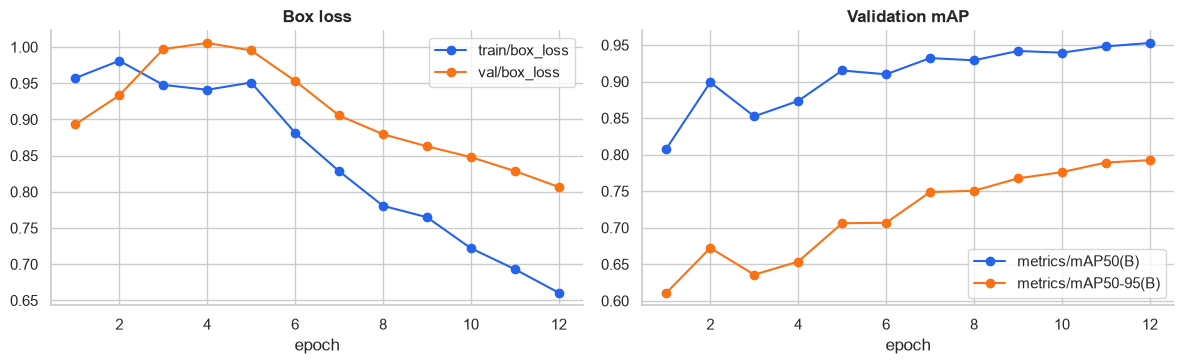

In [8]:
curves = pd.read_csv(Path(model.trainer.save_dir) / "results.csv")
curves.columns = curves.columns.str.strip()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
curves.plot(x="epoch", y=["train/box_loss", "val/box_loss"], marker="o", ax=axes[0], title="Box loss")
curves.plot(x="epoch", y=["metrics/mAP50(B)", "metrics/mAP50-95(B)"], marker="o", ax=axes[1], title="Validation mAP")
plt.tight_layout(); plt.show()

In [9]:
checkpoint("wildlife/train", xp=60)

✅ Checkpoint · wildlife/train (+60 XP)
   ██████████████░░░░░░░░░░ 60/100 XP


## 4. Per-class performance and the test set 📊

The global mAP hides differences between species. Then, the real exam: the **test** split, never seen during
training or model selection.

In [10]:
best = YOLO(str(Path(model.trainer.save_dir) / "weights" / "best.pt"))
test_metrics = best.val(data=str(data_yaml), split="test", imgsz=416, batch=16, device=DEVICE, plots=False,
                        project=str(RUNS_DIR / "wildlife"), name="test", exist_ok=True)
per_class = pd.DataFrame({
    "class": [NAMES[i] for i in range(len(NAMES))],
    "AP50": test_metrics.box.all_ap[:, 0].round(3),
    "AP50-95": test_metrics.box.maps.round(3),
})
print(f"🏁 Test mAP50 = {test_metrics.box.map50:.3f} · mAP50-95 = {test_metrics.box.map:.3f}")
per_class

🏁 Test mAP50 = 0.976 · mAP50-95 = 0.820


,class,AP50,AP50-95
0,buffalo,0.968,0.842
1,elephant,0.980,0.814
2,rhino,0.992,0.878
3,zebra,0.965,0.745


## 5. Choosing the confidence threshold 🎚️

Each predicted box has a confidence. A **low threshold** finds more animals (fewer misses) but adds false alarms; a
**high threshold** gives clean but incomplete results. For a wildlife census, missing animals is bad; for an
anti-poaching alert, false alarms waste rangers' time. The right threshold depends on the use case.

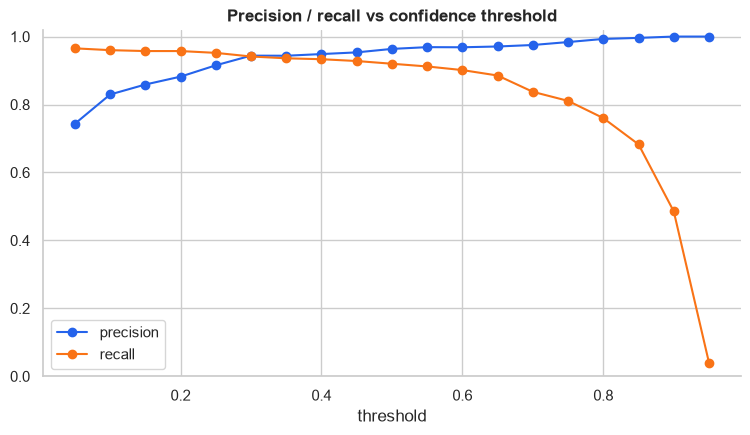

,threshold,precision,recall,false_alarms,missed
1,0.10,0.829,0.960,74,15
4,0.25,0.915,0.952,33,18
9,0.50,0.964,0.920,13,30
14,0.75,0.984,0.811,5,71


In [11]:
test_imgs = sorted((root / "images" / "test").glob("*.jpg"))
preds = best.predict(test_imgs, conf=0.05, imgsz=416, device=DEVICE, verbose=False)

def count_errors(threshold, iou_thr=0.5):
    from torchvision.ops import box_iou
    import torch
    tp = fp = fn = 0
    for r, path in zip(preds, test_imgs):
        keep = r.boxes.conf >= threshold
        pb, pc = r.boxes.xyxy[keep].cpu(), r.boxes.cls[keep].cpu()
        H, W = r.orig_shape
        gt = [list(map(float, l.split())) for l in (root / "labels" / "test" / f"{path.stem}.txt").read_text().splitlines()]
        gb = torch.tensor([[(x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H] for _, x, y, w, h in gt]).reshape(-1, 4)
        gc = torch.tensor([c for c, *_ in gt])
        matched = set()
        if len(pb) and len(gb):
            ious = box_iou(pb, gb)
            for i in torch.argsort(r.boxes.conf[keep].cpu(), descending=True).tolist():
                cands = [(ious[i, j].item(), j) for j in range(len(gb)) if j not in matched and gc[j] == pc[i]]
                best_iou, j = max(cands, default=(0, None))
                if best_iou >= iou_thr:
                    matched.add(j); tp += 1
                else:
                    fp += 1
        else:
            fp += len(pb)
        fn += len(gb) - len(matched)
    return dict(threshold=threshold, precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), false_alarms=fp, missed=fn)

curve = pd.DataFrame([count_errors(t) for t in np.arange(0.05, 0.96, 0.05)])
ax = curve.plot(x="threshold", y=["precision", "recall"], marker="o", title="Precision / recall vs confidence threshold")
ax.set_ylim(0, 1.02); plt.show()
curve.iloc[[1, 4, 9, 14]].round(3)

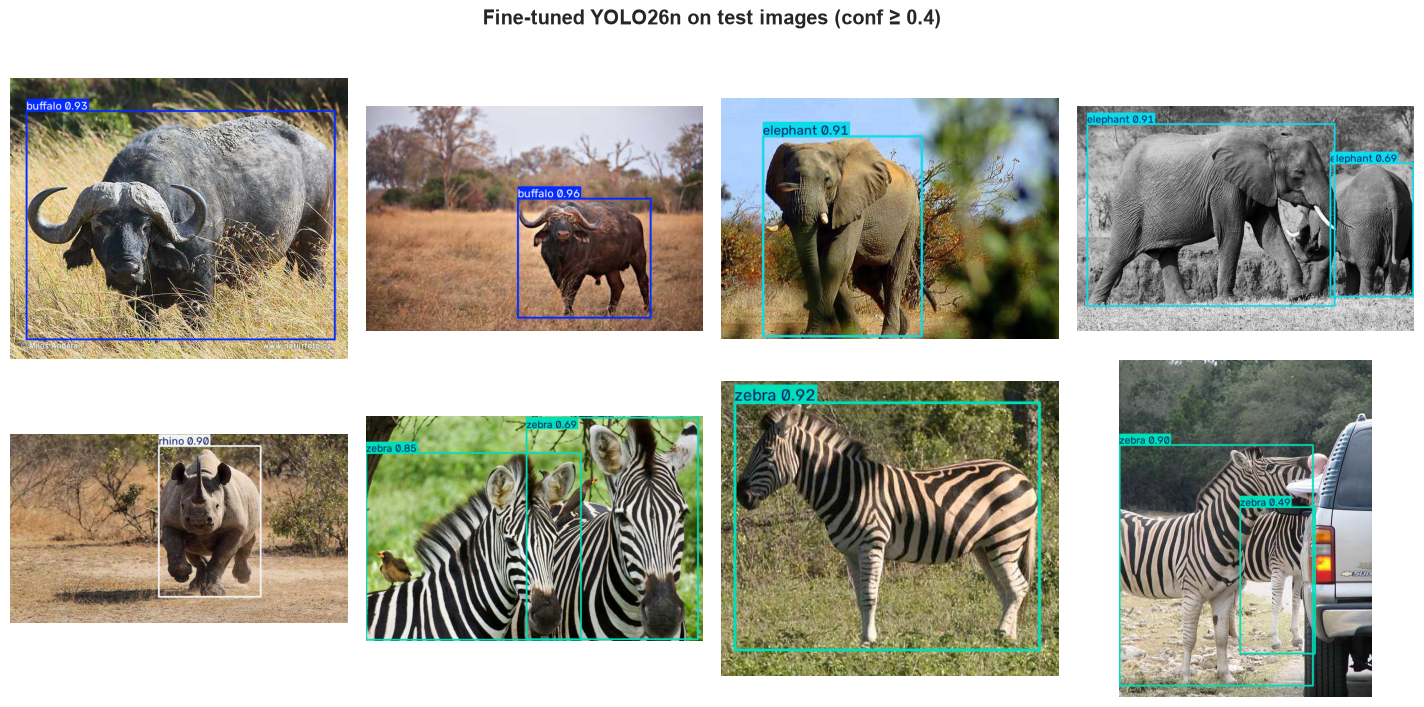

In [12]:
sample = [test_imgs[i] for i in np.linspace(0, len(test_imgs) - 1, 8).astype(int)]
res = best.predict(sample, conf=0.4, imgsz=416, device=DEVICE)
show_images([r.plot()[..., ::-1] for r in res], ncols=4, size=3.6, suptitle="Fine-tuned YOLO26n on test images (conf ≥ 0.4)")

## 6. The wildlife census 🐘🦓 and a submission file

Detection becomes counting: for each image, count the boxes of each species above the chosen threshold. We also
export all detections in a typical competition format (one row per box).

In [13]:
THRESHOLD = 0.4
rows = []
for r, path in zip(preds, test_imgs):
    for (x1, y1, x2, y2), c, s in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()):
        if s >= THRESHOLD:
            rows.append(dict(image_id=path.stem, label=NAMES[int(c)], confidence=round(float(s), 4),
                             xmin=round(x1, 1), ymin=round(y1, 1), xmax=round(x2, 1), ymax=round(y2, 1)))
detections = pd.DataFrame(rows)
make_submission(detections, "african_wildlife_detections.csv")

census = pd.DataFrame({
    "counted by the model": detections["label"].value_counts(),
    "true count": boxes[boxes.split == "test"]["cls"].value_counts(),
})
census["error_%"] = (100 * (census["counted by the model"] - census["true count"]) / census["true count"]).round(1)
census

📤 Submission saved: submissions/african_wildlife_detections.csv  (369 rows, columns=['image_id', 'label', 'confidence', 'xmin', 'ymin', 'xmax', 'ymax'])


,counted by the model,true count,error_%
zebra,130,135,-3.7
elephant,100,99,1.0
rhino,73,75,-2.7
buffalo,66,66,0.0


## 🏁 Mission accomplished

In about 15 minutes, a 2.4 M-parameter model learnt to find and name four species, and to count them within a few
percent of the truth on photos it had never seen.

### 🚀 Your turn (bonus XP)
1. Train longer (`epochs=40`) or bigger (`imgsz=640`): how much mAP do you gain per extra minute?
2. Try the larger `yolo26s.pt`. Is it worth the extra compute?
3. Find the test images where the census is wrong (missed or extra animals) and look at them: small animals? herds?
4. Export the model for a phone or a Raspberry Pi: `best.export(format="onnx")`.

In [14]:
checkpoint("wildlife/complete", xp=140)
badge("AI Ranger", "🦏")
progress()

✅ Checkpoint · wildlife/complete (+140 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ████████████░░░░░░░░░░░░ 200/300 XP
╔══════════════════════════════╗
║ 🦏  BADGE UNLOCKED: AI Ranger ║
╚══════════════════════════════╝
🐣 Data Explorer
████████████░░░░░░░░░░░░ 200/300 XP
Checkpoints unlocked: 2
Badges: 🦏 AI Ranger
